# Quieter note entries: compare before adding complexity
Hypothesis: a sharp level drop followed by changed pitch can recover entries
missed by an increase-only attack detector. A drop alone can also be muting.
Keep the old pitch and attack calculations fixed. Add ONE corroboration rule:
different adjacent pitch groups + sharp drop within the preceding 100 ms.
Reuse the existing 1.5 ratio and 3x reference scale, reversing the ratio for
decreases. 100 ms matches the pitch window, allowing delayed pitch evidence.
These are hypotheses, not tuned constants. No filenames/expected notes enter
the helper. It cannot establish whether a transition was picked or legato.


In [1]:
from pathlib import Path
import csv
import hashlib
import json
import matplotlib.pyplot as plt
from quieter_transitions import find_quieter_entries

folder = Path('outputs/pitch_tracking/personal_2026-11-03')
session = json.loads(Path('data/recording_sessions/2026-11-03_personal_takes.json').read_text())
if not (folder/'audit.json').exists():
    raise FileNotFoundError('Run personal_recordings_lesson.py first.')
audit = json.loads((folder/'audit.json').read_text())
output = folder/'quieter_entries'; output.mkdir(exist_ok=True)

def read_rows(path):
    with path.open() as handle:
        rows = list(csv.DictReader(handle))
    for row in rows:
        for key,value in row.items():
            try: row[key] = float(value)
            except ValueError: pass
    return rows


## 1. Apply the same rule to every included take
Existing pitch groups are evidence, not ground truth. The helper adds quieter
transition proposals without rewriting groups or declaring final note events.
Its marker is a 10 ms measurement midpoint, not an exact physical onset.


In [2]:
results = {}
for item in session['recordings']:
    key = item['id']
    assert hashlib.sha256(Path(item['path']).read_bytes()).hexdigest() == audit[key]['sha256'], 'Rerun experiment 08: audio changed'
    energy = read_rows(folder/f'{key}_energy_rise.csv')
    groups = read_rows(folder/f'{key}_note_evidence.csv')
    pitch = read_rows(folder/f'{key}_windows.csv')
    reference = pitch[0]['reference_rms']
    entries = find_quieter_entries(groups, energy, reference)
    results[key] = dict(energy=energy, groups=groups, pitch=pitch, entries=entries)
    print(key, [(e['from_note'],e['to_note'],round(e['change_midpoint_seconds'],3)) for e in entries])
    (output/f'{key}_entries.json').write_text(json.dumps(entries,indent=2)+'\n')


baseline [('A3', 'G3', 1.733), ('G3', 'E3', 2.09), ('E3', 'D3', 2.436), ('D3', 'G3', 2.841), ('G3', 'E3', 3.238), ('E3', 'D3', 3.565), ('D3', 'C3', 3.948), ('C3', 'E3', 4.303), ('E3', 'D3', 4.728), ('D3', 'C3', 5.048), ('C3', 'A2', 5.459)]
dynamics [('A3', 'G3', 1.923), ('G3', 'E3', 2.356), ('D3', 'G3', 3.096), ('G3', 'E3', 3.551), ('E3', 'D3', 3.93), ('D3', 'C3', 4.349), ('E3', 'D3', 5.143), ('D3', 'C3', 5.564), ('C3', 'A2', 5.976)]
faster [('A3', 'G3', 0.674), ('G3', 'E3', 0.983), ('D3', 'G3', 1.474), ('E3', 'D3', 2.122), ('C3', 'E3', 2.725), ('E3', 'D3', 3.066), ('D3', 'C3', 3.345), ('C3', 'A2', 3.655)]
c_to_a [('C3', 'A2', 4.156), ('C3', 'A2', 10.773)]
fastest [('A3', 'G3', 1.29), ('G3', 'E3', 1.446), ('E3', 'D3', 1.611), ('G3', 'E3', 2.026), ('E3', 'D3', 2.152), ('D3', 'C3', 2.334), ('C3', 'E3', 2.483), ('E3', 'D3', 2.725), ('D3', 'C3', 2.901), ('C3', 'A2', 3.054)]


## 2. Compare transition, ordinary decay, and stopping
Blue/orange: current RMS and recent baseline. Signed change is negative when
level falls. Green pitch points passed existing checks. Purple lines mark
combined drop+pitch proposals; a negative dip alone does not create a marker.
Regions below are chosen for inspection ONLY and never enter the detector.
The stopping region is an apparent cutoff in the waveform, not a manually
verified physical mute. The agent has not listened or assigned exact onsets.


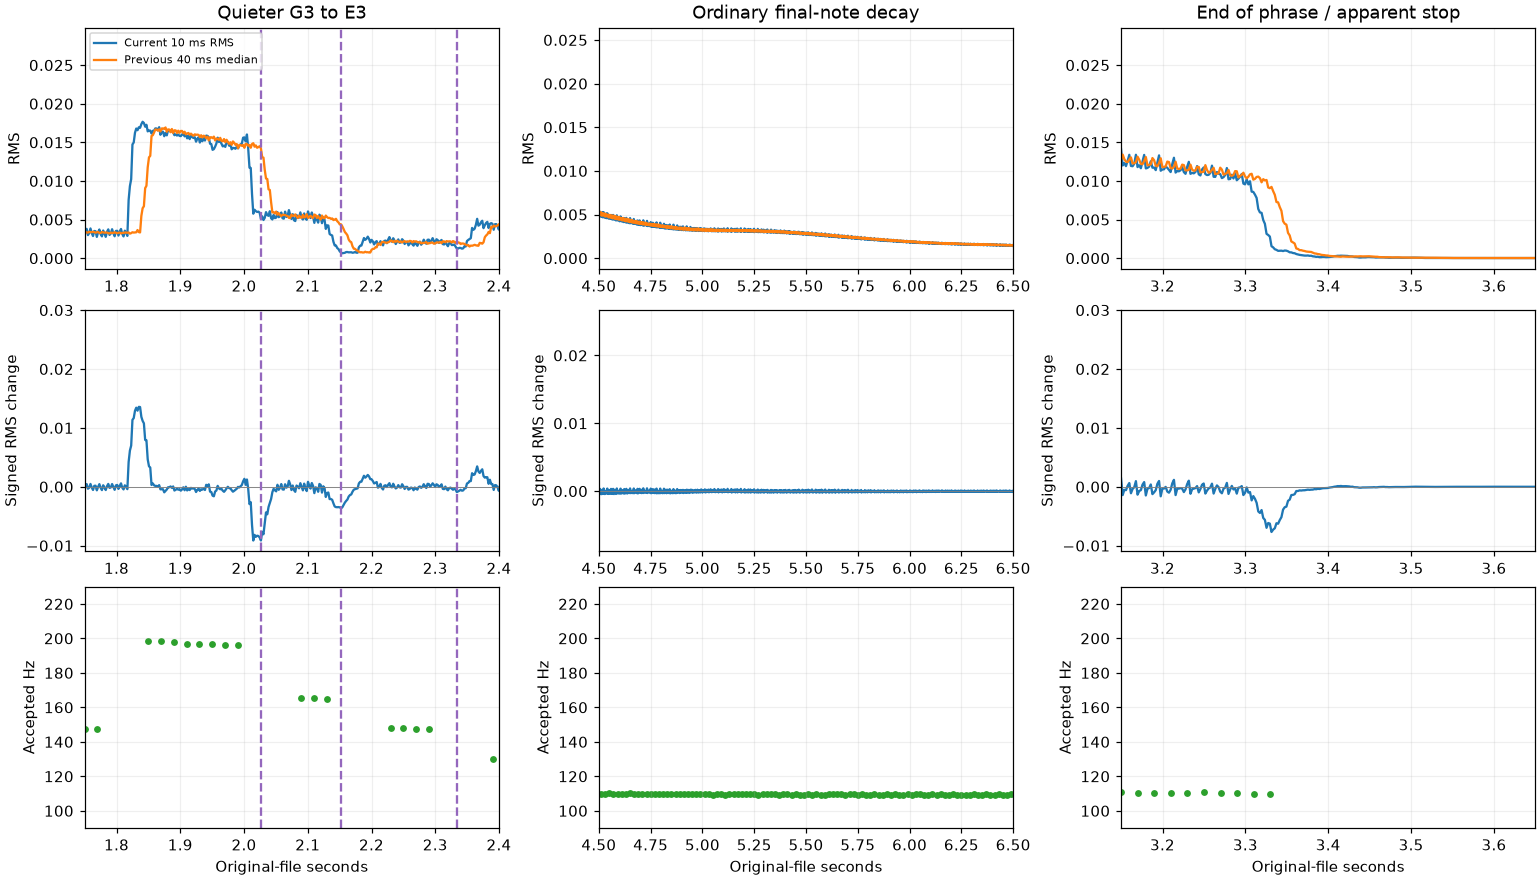

In [3]:
views = [('fastest',1.75,2.4,'Quieter G3 to E3'),
         ('faster',4.5,6.5,'Ordinary final-note decay'),
         ('fastest',3.15,3.65,'End of phrase / apparent stop')]
fig, axes = plt.subplots(3,3,figsize=(14,8),constrained_layout=True)
for column,(key,start,stop,title) in enumerate(views):
    r = results[key]
    times = [e['midpoint_seconds'] for e in r['energy']]
    axes[0,column].plot(times,[e['current_rms'] for e in r['energy']],label='Current 10 ms RMS')
    axes[0,column].plot(times,[e['past_median_rms'] for e in r['energy']],label='Previous 40 ms median')
    axes[0,column].set(title=title,ylabel='RMS')
    axes[1,column].plot(times,[e['signed_change'] for e in r['energy']],color='tab:blue')
    axes[1,column].axhline(0,color='gray',linewidth=.6)
    axes[1,column].set(ylabel='Signed RMS change')
    accepted=[p for p in r['pitch'] if p['accepted']=='True']
    axes[2,column].scatter([p['midpoint_seconds'] for p in accepted], [p['candidate_hz'] for p in accepted],s=12,color='tab:green')
    axes[2,column].set(ylabel='Accepted Hz',xlabel='Original-file seconds',ylim=(90,230))
    for ax in axes[:,column]:
        ax.set_xlim(start,stop);ax.grid(alpha=.2)
        for e in r['entries']:
            if start <= e['change_midpoint_seconds'] <= stop:
                ax.axvline(e['change_midpoint_seconds'],color='tab:purple',linestyle='--')
axes[0,0].legend(fontsize=7)
fig.savefig(output/'transition_decay_stop.png',dpi=140)
plt.show()


## Interpretation and MVP boundary
A changed stable pitch can rescue a quieter entry without treating every drop
as a note. The original increase-based detector still handles repeated picks.
This small rule is supplementary evidence, not a replacement attack detector
and not a full event assembler. Wrong pitch groups can create wrong proposals;
a quiet re-pick of the SAME pitch is not covered. Bends/slides require later
treatment. Shared background calibration remains provisional.
Next combine evidence into a minimal event table, preserving source/reason and
approximate timing. Use a new recording for evaluation after freezing that
version. Do not tune thresholds to force 12 events or chase every tail anomaly.
